# MINDsmall Exploratory Data Analysis

## Part 2.2: Impression, Exposure and Interaction Dynamics

This notebook examines the structure of recommendation impressions, user click
behaviour, feedback semantics, interaction sparsity, article popularity and
temporal interaction patterns in the combined MINDsmall training and validation datasets.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

sns.set_theme(style="whitegrid")

In [2]:
current_folder = Path.cwd()

possible_roots = [
    current_folder,
    current_folder.parent
]

PROJECT_ROOT = next(
    root for root in possible_roots
    if (root / "data" / "raw" / "train" / "behaviors.tsv").exists()
)

TRAIN_DIR = PROJECT_ROOT / "data" / "raw" / "train"
VALID_DIR = PROJECT_ROOT / "data" / "raw" / "valid"

print("Current working folder:", current_folder)
print("Project root:", PROJECT_ROOT)
print("Training data found:", TRAIN_DIR.exists())
print("Validation data found:", VALID_DIR.exists())

Current working folder: /Users/charlenephua/Library/Mobile Documents/com~apple~CloudDocs/uni/Y4/y4s1/bt4222/Project/bt4222-group12/data_preparation
Project root: /Users/charlenephua/Library/Mobile Documents/com~apple~CloudDocs/uni/Y4/y4s1/bt4222/Project/bt4222-group12
Training data found: True
Validation data found: True


In [3]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "data_preparation"
    else Path.cwd()
)

TRAIN_DIR = PROJECT_ROOT / "data" / "raw" / "train"
VALID_DIR = PROJECT_ROOT / "data" / "raw" / "valid"

BEHAVIOR_COLUMNS = [
    "impression_id",
    "user_id",
    "time",
    "history",
    "impressions"
]

NEWS_COLUMNS = [
    "news_id",
    "category",
    "subcategory",
    "title",
    "abstract",
    "url",
    "title_entities",
    "abstract_entities"
]

In [4]:
train_behaviors = pd.read_csv(
    TRAIN_DIR / "behaviors.tsv",
    sep="\t",
    header=None,
    names=BEHAVIOR_COLUMNS
)

valid_behaviors = pd.read_csv(
    VALID_DIR / "behaviors.tsv",
    sep="\t",
    header=None,
    names=BEHAVIOR_COLUMNS
)

# Retain the original source
train_behaviors["source_split"] = "train"
valid_behaviors["source_split"] = "validation"

behaviors = pd.concat(
    [train_behaviors, valid_behaviors],
    ignore_index=True
)

behaviors["time"] = pd.to_datetime(
    behaviors["time"],
    format="%m/%d/%Y %I:%M:%S %p"
)

# Impression IDs may restart in each source file
behaviors["global_impression_id"] = (
    behaviors["source_split"]
    + "_"
    + behaviors["impression_id"].astype(str)
)

behaviors = behaviors.sort_values("time").reset_index(drop=True)

print("Training impressions:", f"{len(train_behaviors):,}")
print("Validation impressions:", f"{len(valid_behaviors):,}")
print("Combined impressions:", f"{len(behaviors):,}")
print("Unique users:", f"{behaviors['user_id'].nunique():,}")
print(
    "Observation period:",
    behaviors["time"].min(),
    "to",
    behaviors["time"].max()
)

display(behaviors.head())

Training impressions: 156,965
Validation impressions: 73,152
Combined impressions: 230,117
Unique users: 94,057
Observation period: 2019-11-09 00:00:19 to 2019-11-15 23:58:03


,impression_id,user_id,time,history,impressions,source_split,global_impression_id
0,20112,U65916,2019-11-09 00:00:19,N51706 N40767 N12096 N9798 N38802 N54827 N57801 N5184 N23653 N44007 N36443 N43142 N11143 N53652 ...,N54300-0 N46057-1 N57005-0 N52154-0 N57099-0 N31002-0 N37108-0 N58075-0 N2678-0 N53652-0 N15134-...,train,train_20112
1,13807,U49985,2019-11-09 00:01:13,N5056 N29975 N53234 N39603 N50032 N8422 N53580 N63314 N62646 N23203 N10807 N33835 N50455 N7242 N...,N20602-0 N50059-0 N57768-1 N50135-1 N15134-0 N16560-1 N61880-0 N64536-0 N37108-0 N43001-0 N6868-...,train,train_13807
2,27660,U25550,2019-11-09 00:02:44,N17260 N38298 N33976 N47719 N14888 N18870 N4607,N50135-0 N15134-0 N52433-1 N20602-0 N64536-0,train,train_27660
3,152217,U19710,2019-11-09 00:02:50,N3530 N48284 N43019 N62546 N138 N13138 N10676 N41244,N57099-0 N30295-0 N21086-0 N5379-0 N57005-0 N43083-1 N31002-0 N6868-0 N43587-0 N3491-0 N41617-0 ...,train,train_152217
4,42166,U38106,2019-11-09 00:03:09,N16874 N264 N48697 N51366,N3491-0 N20602-0 N25785-0 N23575-0 N38783-0 N18708-0 N58075-0 N28684-0 N8913-0 N15134-0 N5889-0 ...,train,train_42166


In [5]:
train_news = pd.read_csv(
    TRAIN_DIR / "news.tsv",
    sep="\t",
    header=None,
    names=NEWS_COLUMNS
)

valid_news = pd.read_csv(
    VALID_DIR / "news.tsv",
    sep="\t",
    header=None,
    names=NEWS_COLUMNS
)

train_news["source_split"] = "train"
valid_news["source_split"] = "validation"

news_all_rows = pd.concat(
    [train_news, valid_news],
    ignore_index=True
)

# Record every split in which the article appears
article_split_presence = (
    news_all_rows
    .groupby("news_id")["source_split"]
    .agg(lambda x: ", ".join(sorted(set(x))))
    .rename("split_presence")
    .reset_index()
)

# Keep one metadata row per article
news = (
    news_all_rows
    .drop(columns="source_split")
    .drop_duplicates(subset="news_id", keep="first")
    .merge(
        article_split_presence,
        on="news_id",
        how="left"
    )
    .reset_index(drop=True)
)

print("News rows before deduplication:", f"{len(news_all_rows):,}")
print("Unique articles after deduplication:", f"{len(news):,}")

display(news.head())

News rows before deduplication: 93,698
Unique articles after deduplication: 65,238


,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities,split_presence
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, and Prince Philip Swear By","Shop the notebooks, jackets, and more that the royals can't live without.",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"", ""Type"": ""P"", ""WikidataId"": ""Q80976"", ""Confidence""...",[],"train, validation"
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding you back and keeping you from shedding that unwanted...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""WikidataId"": ""Q193583"", ""Confidence"": 1.0, ""Occurrenc...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""WikidataId"": ""Q193583"", ""Confidence"": 1.0, ""Occurrenc...",train
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches of Ukraine's War,Lt. Ivan Molchanets peeked over a parapet of sand bags at the front line of the war in Ukraine. ...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId"": ""Q212"", ""Confidence"": 0.946, ""OccurrenceOffsets...","train, validation"
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My Mental Health.,"I felt like I was a fraud, and being an NBA wife didn't help that. In fact, it nearly destroyed me.",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ""Type"": ""O"", ""WikidataId"": ""Q155223"", ""Confidence""...","train, validation"
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a Dermatologist","They seem harmless, but there's a very good reason you shouldn't ignore them. The post How to Ge...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataId"": ""Q3179593"", ""Confidence"": 1.0, ""OccurrenceOffs...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataId"": ""Q3179593"", ""Confidence"": 1.0, ""OccurrenceOffs...","train, validation"


In [6]:
assert len(behaviors) == len(train_behaviors) + len(valid_behaviors)
assert behaviors["global_impression_id"].is_unique
assert news["news_id"].is_unique

merge_summary = pd.Series({
    "Behaviour records": len(behaviors),
    "Unique impressions": behaviors["global_impression_id"].nunique(),
    "Unique users": behaviors["user_id"].nunique(),
    "Unique articles in news files": news["news_id"].nunique(),
    "Earliest impression": behaviors["time"].min(),
    "Latest impression": behaviors["time"].max()
})

display(merge_summary)

print("Merge completed successfully.")

Behaviour records                             230117
Unique impressions                            230117
Unique users                                   94057
Unique articles in news files                  65238
Earliest impression              2019-11-09 00:00:19
Latest impression                2019-11-15 23:58:03
dtype: object

Merge completed successfully.


In [7]:
behaviors.head()
#behaviors.info()

,impression_id,user_id,time,history,impressions,source_split,global_impression_id
0,20112,U65916,2019-11-09 00:00:19,N51706 N40767 N12096 N9798 N38802 N54827 N57801 N5184 N23653 N44007 N36443 N43142 N11143 N53652 ...,N54300-0 N46057-1 N57005-0 N52154-0 N57099-0 N31002-0 N37108-0 N58075-0 N2678-0 N53652-0 N15134-...,train,train_20112
1,13807,U49985,2019-11-09 00:01:13,N5056 N29975 N53234 N39603 N50032 N8422 N53580 N63314 N62646 N23203 N10807 N33835 N50455 N7242 N...,N20602-0 N50059-0 N57768-1 N50135-1 N15134-0 N16560-1 N61880-0 N64536-0 N37108-0 N43001-0 N6868-...,train,train_13807
2,27660,U25550,2019-11-09 00:02:44,N17260 N38298 N33976 N47719 N14888 N18870 N4607,N50135-0 N15134-0 N52433-1 N20602-0 N64536-0,train,train_27660
3,152217,U19710,2019-11-09 00:02:50,N3530 N48284 N43019 N62546 N138 N13138 N10676 N41244,N57099-0 N30295-0 N21086-0 N5379-0 N57005-0 N43083-1 N31002-0 N6868-0 N43587-0 N3491-0 N41617-0 ...,train,train_152217
4,42166,U38106,2019-11-09 00:03:09,N16874 N264 N48697 N51366,N3491-0 N20602-0 N25785-0 N23575-0 N38783-0 N18708-0 N58075-0 N28684-0 N8913-0 N15134-0 N5889-0 ...,train,train_42166


In [8]:
news.head()

,news_id,category,subcategory,title,abstract,url,title_entities,abstract_entities,split_presence
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, and Prince Philip Swear By","Shop the notebooks, jackets, and more that the royals can't live without.",https://assets.msn.com/labs/mind/AAGH0ET.html,"[{""Label"": ""Prince Philip, Duke of Edinburgh"", ""Type"": ""P"", ""WikidataId"": ""Q80976"", ""Confidence""...",[],"train, validation"
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,These seemingly harmless habits are holding you back and keeping you from shedding that unwanted...,https://assets.msn.com/labs/mind/AAB19MK.html,"[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""WikidataId"": ""Q193583"", ""Confidence"": 1.0, ""Occurrenc...","[{""Label"": ""Adipose tissue"", ""Type"": ""C"", ""WikidataId"": ""Q193583"", ""Confidence"": 1.0, ""Occurrenc...",train
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches of Ukraine's War,Lt. Ivan Molchanets peeked over a parapet of sand bags at the front line of the war in Ukraine. ...,https://assets.msn.com/labs/mind/AAJgNsz.html,[],"[{""Label"": ""Ukraine"", ""Type"": ""G"", ""WikidataId"": ""Q212"", ""Confidence"": 0.946, ""OccurrenceOffsets...","train, validation"
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My Mental Health.,"I felt like I was a fraud, and being an NBA wife didn't help that. In fact, it nearly destroyed me.",https://assets.msn.com/labs/mind/AACk2N6.html,[],"[{""Label"": ""National Basketball Association"", ""Type"": ""O"", ""WikidataId"": ""Q155223"", ""Confidence""...","train, validation"
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a Dermatologist","They seem harmless, but there's a very good reason you shouldn't ignore them. The post How to Ge...",https://assets.msn.com/labs/mind/AAAKEkt.html,"[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataId"": ""Q3179593"", ""Confidence"": 1.0, ""OccurrenceOffs...","[{""Label"": ""Skin tag"", ""Type"": ""C"", ""WikidataId"": ""Q3179593"", ""Confidence"": 1.0, ""OccurrenceOffs...","train, validation"


In [9]:
sample = behaviors.iloc[0]

print("Impression ID:")
print(sample["impression_id"])

print("\nUser ID:")
print(sample["user_id"])

print("\nTime:")
print(sample["time"])

print("\nPreviously clicked articles:")
print(sample["history"])

print("\nArticles shown in this impression:")
print(sample["impressions"])

Impression ID:
20112

User ID:
U65916

Time:
2019-11-09 00:00:19

Previously clicked articles:
N51706 N40767 N12096 N9798 N38802 N54827 N57801 N5184 N23653 N44007 N36443 N43142 N11143 N53652 N2678

Articles shown in this impression:
N54300-0 N46057-1 N57005-0 N52154-0 N57099-0 N31002-0 N37108-0 N58075-0 N2678-0 N53652-0 N15134-0 N7938-0 N50135-0 N16560-0 N64536-0 N1972-0 N52433-0 N61880-0 N57768-0 N28684-0 N5379-0 N33291-0 N55582-1 N37377-0 N41858-1 N6868-0 N18546-0 N20602-0 N43001-0 N25785-0 N50329-0


In [10]:
print("Behavior column types:")
display(behaviors.dtypes)

print("\nBehavior missing values:")
display(behaviors.isna().sum())

print("\nNews column types:")
display(news.dtypes)

print("\nNews missing values:")
display(news.isna().sum())

Behavior column types:


impression_id                    int64
user_id                         object
time                    datetime64[ns]
history                         object
impressions                     object
source_split                    object
global_impression_id            object
dtype: object


Behavior missing values:


impression_id              0
user_id                    0
time                       0
history                 5452
impressions                0
source_split               0
global_impression_id       0
dtype: int64


News column types:


news_id              object
category             object
subcategory          object
title                object
abstract             object
url                  object
title_entities       object
abstract_entities    object
split_presence       object
dtype: object


News missing values:


news_id                 0
category                0
subcategory             0
title                   0
abstract             3415
url                     0
title_entities          3
abstract_entities       4
split_presence          0
dtype: int64

In [11]:
print(behaviors.shape)
print(news.shape)
display(behaviors.head())
display(behaviors.isna().sum())

(230117, 7)
(65238, 9)


,impression_id,user_id,time,history,impressions,source_split,global_impression_id
0,20112,U65916,2019-11-09 00:00:19,N51706 N40767 N12096 N9798 N38802 N54827 N57801 N5184 N23653 N44007 N36443 N43142 N11143 N53652 ...,N54300-0 N46057-1 N57005-0 N52154-0 N57099-0 N31002-0 N37108-0 N58075-0 N2678-0 N53652-0 N15134-...,train,train_20112
1,13807,U49985,2019-11-09 00:01:13,N5056 N29975 N53234 N39603 N50032 N8422 N53580 N63314 N62646 N23203 N10807 N33835 N50455 N7242 N...,N20602-0 N50059-0 N57768-1 N50135-1 N15134-0 N16560-1 N61880-0 N64536-0 N37108-0 N43001-0 N6868-...,train,train_13807
2,27660,U25550,2019-11-09 00:02:44,N17260 N38298 N33976 N47719 N14888 N18870 N4607,N50135-0 N15134-0 N52433-1 N20602-0 N64536-0,train,train_27660
3,152217,U19710,2019-11-09 00:02:50,N3530 N48284 N43019 N62546 N138 N13138 N10676 N41244,N57099-0 N30295-0 N21086-0 N5379-0 N57005-0 N43083-1 N31002-0 N6868-0 N43587-0 N3491-0 N41617-0 ...,train,train_152217
4,42166,U38106,2019-11-09 00:03:09,N16874 N264 N48697 N51366,N3491-0 N20602-0 N25785-0 N23575-0 N38783-0 N18708-0 N58075-0 N28684-0 N8913-0 N15134-0 N5889-0 ...,train,train_42166


impression_id              0
user_id                    0
time                       0
history                 5452
impressions                0
source_split               0
global_impression_id       0
dtype: int64

### Basic Behaviour Dataset Statistics

Each row in `behaviors.tsv` represents one recommendation impression shown to a
user at a particular time. The `history` field records articles clicked before
the impression, while `impressions` contains the exposed candidate articles and
their click labels.

In [12]:
# Convert the time column from text to datetime
behaviors["time"] = pd.to_datetime(
    behaviors["time"],
    format="%m/%d/%Y %I:%M:%S %p"
)

basic_statistics = pd.Series({
    "Total impression records": len(behaviors),
    "Unique impression IDs": behaviors["global_impression_id"].nunique(),
    "Unique users": behaviors["user_id"].nunique(),
    "Unique news articles": news["news_id"].nunique(),
    "Earliest impression": behaviors["time"].min(),
    "Latest impression": behaviors["time"].max(),
    "Missing histories": behaviors["history"].isna().sum(),
    "Missing history percentage": (
        behaviors["history"].isna().mean() * 100
    ),
    "Duplicate global impression IDs": behaviors["global_impression_id"].duplicated().sum(),
    "Duplicate news IDs": news["news_id"].duplicated().sum()
})

display(basic_statistics)

Total impression records                        230117
Unique impression IDs                           230117
Unique users                                     94057
Unique news articles                             65238
Earliest impression                2019-11-09 00:00:19
Latest impression                  2019-11-15 23:58:03
Missing histories                                 5452
Missing history percentage                     2.36923
Duplicate global impression IDs                      0
Duplicate news IDs                                   0
dtype: object

The MINDsmall behaviour data contains 230,117 impression records, while the accompanying news metadata contains 94,057 articles. All essential impression fields are complete. However, 5,452 impressions (2.37%) have no recorded user history, indicating that a small subset of impressions must be handled without prior click information.

### Expanding Impression Slates

The raw `impressions` column stores multiple exposed articles in one string.
Each item follows the format `news_id-label`, where label 1 represents a click
and label 0 represents an exposed but unclicked article.

We expand this column so that each row represents one article exposure.

In [13]:
# Keep the relevant impression-level information
exposures = behaviors[
    ["global_impression_id", "impression_id", "user_id", "time", "impressions"]
].copy()

# Split each slate into a list of article-label pairs
exposures["candidate"] = exposures["impressions"].str.split()

# Create one row for every article exposure
exposures = exposures.explode("candidate", ignore_index=True)

# Separate the article ID and click label
exposures[["news_id", "label"]] = exposures["candidate"].str.rsplit(
    "-",
    n=1,
    expand=True
)

# Convert the label from text to an integer
exposures["label"] = exposures["label"].astype(int)

# Record each article's position within its impression slate
exposures["position"] = (
    exposures.groupby("global_impression_id").cumcount() + 1
)

# Keep only the useful columns
exposures = exposures[
    [
        "global_impression_id",
        "impression_id",
        "user_id",
        "time",
        "news_id",
        "position",
        "label"
    ]
]

display(exposures.head(10))
print("Exposure-level shape:", exposures.shape)

,global_impression_id,impression_id,user_id,time,news_id,position,label
0,train_20112,20112,U65916,2019-11-09 00:00:19,N54300,1,0
1,train_20112,20112,U65916,2019-11-09 00:00:19,N46057,2,1
2,train_20112,20112,U65916,2019-11-09 00:00:19,N57005,3,0
3,train_20112,20112,U65916,2019-11-09 00:00:19,N52154,4,0
4,train_20112,20112,U65916,2019-11-09 00:00:19,N57099,5,0
5,train_20112,20112,U65916,2019-11-09 00:00:19,N31002,6,0
6,train_20112,20112,U65916,2019-11-09 00:00:19,N37108,7,0
7,train_20112,20112,U65916,2019-11-09 00:00:19,N58075,8,0
8,train_20112,20112,U65916,2019-11-09 00:00:19,N2678,9,0
9,train_20112,20112,U65916,2019-11-09 00:00:19,N53652,10,0


Exposure-level shape: (8584442, 7)


In [14]:
print("Unique labels:", sorted(exposures["label"].unique()))
print("Missing values:")
display(exposures.isna().sum())

print(
    "Unique impressions before expansion:",
    behaviors["global_impression_id"].nunique()
)

print(
    "Unique impressions after expansion:",
    exposures["global_impression_id"].nunique()
)

print(
    "Duplicate impression-article pairs:",
    exposures.duplicated(["global_impression_id", "news_id"]).sum()
)

Unique labels: [0, 1]
Missing values:


global_impression_id    0
impression_id           0
user_id                 0
time                    0
news_id                 0
position                0
label                   0
dtype: int64

Unique impressions before expansion: 230117
Unique impressions after expansion: 230117
Duplicate impression-article pairs: 0


In [15]:
impression_summary = (
    exposures.groupby("global_impression_id")
    .agg(
        user_id=("user_id", "first"),
        time=("time", "first"),
        slate_length=("news_id", "size"),
        click_count=("label", "sum")
    )
    .reset_index()
)

impression_summary["non_click_count"] = (
    impression_summary["slate_length"]
    - impression_summary["click_count"]
)

impression_summary["impression_ctr"] = (
    impression_summary["click_count"]
    / impression_summary["slate_length"]
)

display(impression_summary.head())

,global_impression_id,user_id,time,slate_length,click_count,non_click_count,impression_ctr
0,train_1,U13740,2019-11-11 09:05:58,2,1,1,0.500000
1,train_10,U53231,2019-11-11 11:28:11,2,1,1,0.500000
2,train_100,U70910,2019-11-13 06:48:54,12,1,11,0.083333
3,train_1000,U31709,2019-11-11 21:18:11,7,1,6,0.142857
4,train_10000,U72585,2019-11-12 07:10:43,15,1,14,0.066667


In [16]:
total_impressions = len(impression_summary)
total_exposures = len(exposures)
total_clicks = exposures["label"].sum()
total_non_clicks = total_exposures - total_clicks

overall_ctr = total_clicks / total_exposures

zero_click_impressions = (
    impression_summary["click_count"].eq(0).sum()
)

one_click_impressions = (
    impression_summary["click_count"].eq(1).sum()
)

multiple_click_impressions = (
    impression_summary["click_count"].gt(1).sum()
)

interaction_statistics = pd.Series({
    "Total impressions": total_impressions,
    "Total article exposures": total_exposures,
    "Total clicked exposures": total_clicks,
    "Total unclicked exposures": total_non_clicks,
    "Overall item-level CTR": overall_ctr,
    "Mean slate length": impression_summary["slate_length"].mean(),
    "Median slate length": impression_summary["slate_length"].median(),
    "Minimum slate length": impression_summary["slate_length"].min(),
    "Maximum slate length": impression_summary["slate_length"].max(),
    "Zero-click impressions": zero_click_impressions,
    "One-click impressions": one_click_impressions,
    "Multiple-click impressions": multiple_click_impressions
})

display(interaction_statistics)

Total impressions             2.301170e+05
Total article exposures       8.584442e+06
Total clicked exposures       3.477270e+05
Total unclicked exposures     8.236715e+06
Overall item-level CTR        4.050665e-02
Mean slate length             3.730468e+01
Median slate length           2.400000e+01
Minimum slate length          2.000000e+00
Maximum slate length          2.990000e+02
Zero-click impressions        0.000000e+00
One-click impressions         1.659550e+05
Multiple-click impressions    6.416200e+04
dtype: float64

In [17]:
click_group_percentages = pd.Series({
    "Zero clicks (%)": zero_click_impressions / total_impressions * 100,
    "Exactly one click (%)": one_click_impressions / total_impressions * 100,
    "Multiple clicks (%)": multiple_click_impressions / total_impressions * 100
})

display(click_group_percentages)

Zero clicks (%)           0.000000
Exactly one click (%)    72.117662
Multiple clicks (%)      27.882338
dtype: float64

In [18]:
impression_click_rate = (
    impression_summary["click_count"].gt(0).mean()
)

print(f"Overall item-level CTR: {overall_ctr:.4f}")
print(f"Impression-level click rate: {impression_click_rate:.4f}")

Overall item-level CTR: 0.0405
Impression-level click rate: 1.0000


In [19]:
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

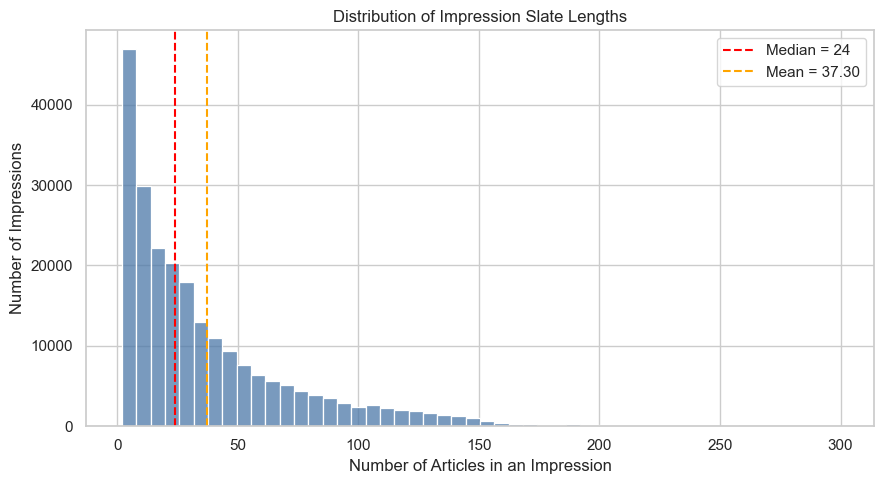

In [20]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=impression_summary,
    x="slate_length",
    bins=50,
    color="#4C78A8"
)

plt.axvline(
    impression_summary["slate_length"].median(),
    color="red",
    linestyle="--",
    label=f'Median = {impression_summary["slate_length"].median():.0f}'
)

plt.axvline(
    impression_summary["slate_length"].mean(),
    color="orange",
    linestyle="--",
    label=f'Mean = {impression_summary["slate_length"].mean():.2f}'
)

plt.title("Distribution of Impression Slate Lengths")
plt.xlabel("Number of Articles in an Impression")
plt.ylabel("Number of Impressions")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "slate_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

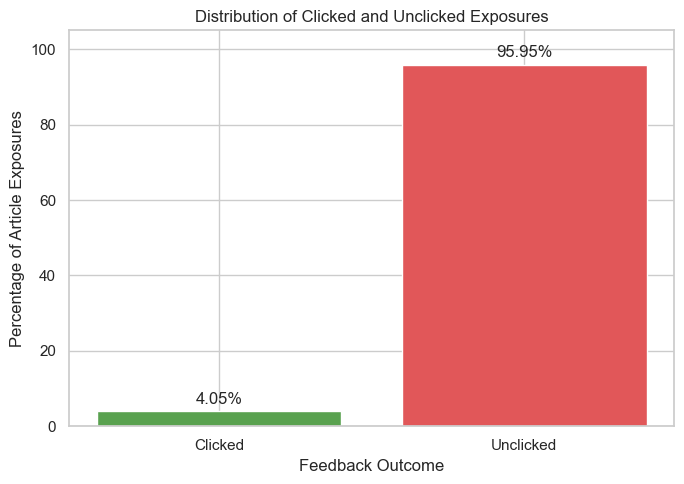

In [21]:
feedback_distribution = pd.DataFrame({
    "Feedback": ["Clicked", "Unclicked"],
    "Count": [total_clicks, total_non_clicks]
})

feedback_distribution["Percentage"] = (
    feedback_distribution["Count"]
    / feedback_distribution["Count"].sum()
    * 100
)

fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    feedback_distribution["Feedback"],
    feedback_distribution["Percentage"],
    color=["#59A14F", "#E15759"]
)

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in feedback_distribution["Percentage"]
    ],
    padding=3
)

ax.set_title("Distribution of Clicked and Unclicked Exposures")
ax.set_xlabel("Feedback Outcome")
ax.set_ylabel("Percentage of Article Exposures")
ax.set_ylim(0, 105)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "clicked_unclicked_exposures.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

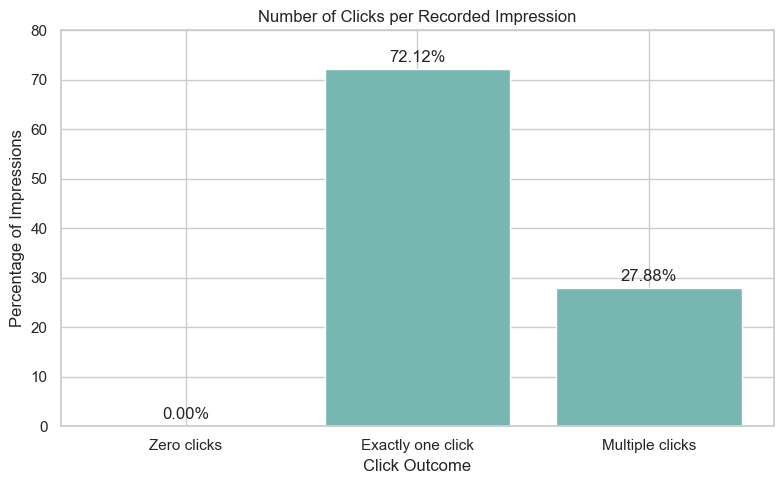

In [22]:
click_groups = pd.DataFrame({
    "Click Group": [
        "Zero clicks",
        "Exactly one click",
        "Multiple clicks"
    ],
    "Percentage": [
        zero_click_impressions / total_impressions * 100,
        one_click_impressions / total_impressions * 100,
        multiple_click_impressions / total_impressions * 100
    ]
})

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    click_groups["Click Group"],
    click_groups["Percentage"],
    color="#76B7B2"
)

ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in click_groups["Percentage"]
    ],
    padding=3
)

ax.set_title("Number of Clicks per Recorded Impression")
ax.set_xlabel("Click Outcome")
ax.set_ylabel("Percentage of Impressions")
ax.set_ylim(0, 80)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "clicks_per_impression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Every recorded training impression contains at least one clicked article. This suggests that the dataset is constructed around impressions containing positive interactions. Consequently, it supports within-impression ranking but cannot be used to estimate the real-world probability that an arbitrary recommendation slate receives any click.

In [23]:
position_summary = (
    exposures.groupby("position")
    .agg(
        exposures=("label", "size"),
        clicks=("label", "sum"),
        ctr=("label", "mean")
    )
    .reset_index()
)

print(position_summary.head(20))
print(position_summary.tail(20))

    position  exposures  clicks       ctr
0          1     230117   24200  0.105164
1          2     230117   24354  0.105833
2          3     215683   17215  0.079816
3          4     211694   15960  0.075392
4          5     202796   13600  0.067062
5          6     197716   12363  0.062529
6          7     193680   11913  0.061509
7          8     183212   10191  0.055624
8          9     179723    9522  0.052982
9         10     175872    9018  0.051276
10        11     169136    8432  0.049853
11        12     163387    7558  0.046258
12        13     157383    7236  0.045977
13        14     153276    6715  0.043810
14        15     148872    6364  0.042748
15        16     145944    6173  0.042297
16        17     142528    5820  0.040834
17        18     137184    5613  0.040916
18        19     134354    5286  0.039344
19        20     131072    4972  0.037933
     position  exposures  clicks       ctr
279       280         86       1  0.011628
280       281         76       0

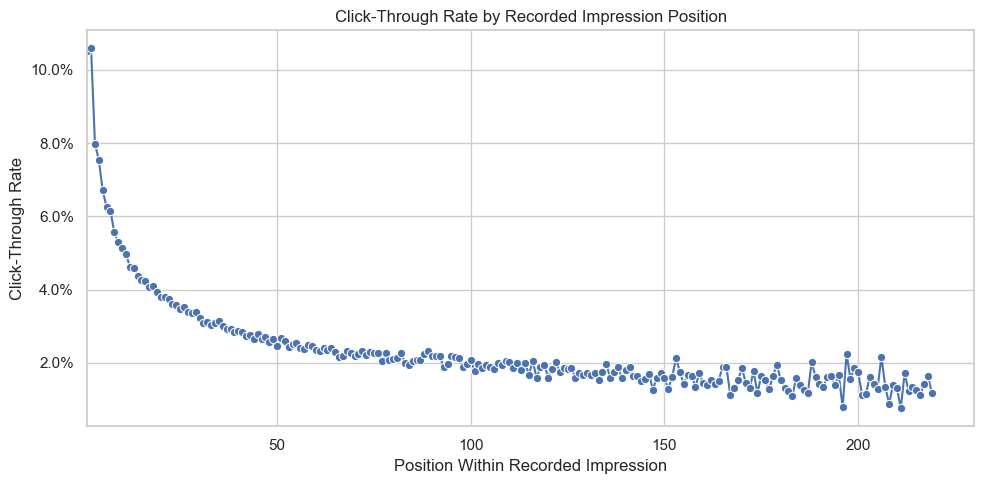

In [24]:
from matplotlib.ticker import PercentFormatter

reliable_positions = position_summary[
    position_summary["exposures"] >= 1000
].copy()

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=reliable_positions,
    x="position",
    y="ctr",
    marker="o",
    ax=ax
)

ax.set_title("Click-Through Rate by Recorded Impression Position")
ax.set_xlabel("Position Within Recorded Impression")
ax.set_ylabel("Click-Through Rate")

ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlim(left=1)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "ctr_by_position.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Positions with fewer than 1,000 recorded exposures were excluded because their CTR estimates were based on small and increasingly sparse samples.

## Interaction Hierarchy and Funnel

MIND records article exposures and binary click outcomes but does not provide
downstream interaction stages such as reading duration, sharing or subscription.
The observable item-level funnel is therefore limited to exposure and click.

In [25]:
funnel_summary = pd.DataFrame({
    "Stage": [
        "Article exposures",
        "Clicked exposures"
    ],
    "Count": [
        total_exposures,
        total_clicks
    ],
    "Percentage of exposures": [
        100,
        overall_ctr * 100
    ]
})

display(funnel_summary)

,Stage,Count,Percentage of exposures
0,Article exposures,8584442,100.000000
1,Clicked exposures,347727,4.050665


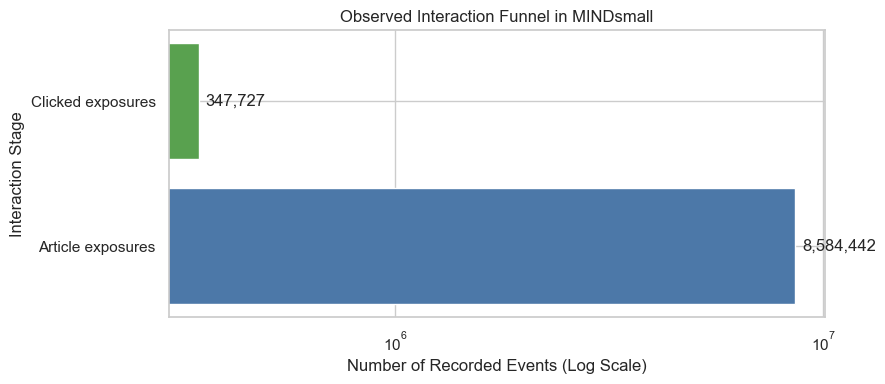

In [26]:
fig, ax = plt.subplots(figsize=(9, 4))

bars = ax.barh(
    funnel_summary["Stage"],
    funnel_summary["Count"],
    color=["#4C78A8", "#59A14F"]
)

ax.set_xscale("log")
ax.set_title("Observed Interaction Funnel in MINDsmall")
ax.set_xlabel("Number of Recorded Events (Log Scale)")
ax.set_ylabel("Interaction Stage")

ax.bar_label(
    bars,
    labels=[
        f"{count:,}"
        for count in funnel_summary["Count"]
    ],
    padding=5
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "interaction_funnel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

| Level            | Starting unit                | Outcome                        |
| ---------------- | ---------------------------- | ------------------------------ |
| Item level       | 5,843,444 article exposures  | 236,344 clicked exposures      |
| Impression level | 156,965 recorded impressions | All contain at least one click |

The observable interaction funnel in MINDsmall is limited to article exposure and click because the dataset does not record downstream behaviours such as reading duration, sharing or subscription. Across 5,843,444 recorded article exposures, 236,344 resulted in clicks, corresponding to an exposure-to-click conversion rate of 4.04%. At the impression level, all 156,965 records contain at least one click. However, this reflects the construction of the available impression logs rather than a real-world 100% engagement rate. 100% of impressions contain a click because zero-click impressions are absent from this training set. It should not be interpreted as real platform conversion. 

Consequently, MIND is suited to comparing clicked and unclicked articles within recorded impressions, but it cannot support analysis of post-click engagement or the likelihood that an arbitrary impression receives no interaction. 

## Feedback Semantics

MIND distinguishes between clicked articles, exposed-but-unclicked articles and
articles for which no user-specific exposure was recorded. These feedback states
should not be interpreted as equally strong preference signals.

In [27]:
feedback_summary = pd.DataFrame({
    "Feedback type": [
        "Clicked",
        "Exposed but unclicked"
    ],
    "Label": [1, 0],
    "Count": [
        total_clicks,
        total_non_clicks
    ],
    "Percentage": [
        total_clicks / total_exposures * 100,
        total_non_clicks / total_exposures * 100
    ]
})

display(feedback_summary)

,Feedback type,Label,Count,Percentage
0,Clicked,1,347727,4.050665
1,Exposed but unclicked,0,8236715,95.949335


In [28]:
user_article_feedback = (
    exposures.groupby(["user_id", "news_id"])
    .agg(
        exposure_count=("label", "size"),
        click_count=("label", "sum"),
        different_labels=("label", "nunique")
    )
    .reset_index()
)

repeated_pairs = user_article_feedback[
    user_article_feedback["exposure_count"] > 1
]

mixed_feedback_pairs = user_article_feedback[
    user_article_feedback["different_labels"] > 1
]

feedback_consistency = pd.Series({
    "Unique exposed user-article pairs": len(user_article_feedback),
    "Pairs exposed more than once": len(repeated_pairs),
    "Pairs observed with both labels": len(mixed_feedback_pairs),
    "Mixed-label percentage among repeated pairs": (
        len(mixed_feedback_pairs) / len(repeated_pairs) * 100
        if len(repeated_pairs) > 0 else 0
    )
})

display(feedback_consistency)

Unique exposed user-article pairs              7.437956e+06
Pairs exposed more than once                   8.903870e+05
Pairs observed with both labels                6.282800e+04
Mixed-label percentage among repeated pairs    7.056258e+00
dtype: float64

In [29]:
print(f"Unique exposed user–article pairs: {len(user_article_feedback):,}")
print(f"Pairs exposed more than once: {len(repeated_pairs):,}")
print(f"Pairs observed with both labels: {len(mixed_feedback_pairs):,}")
print(
    "Mixed-label percentage among repeated pairs: "
    f"{len(mixed_feedback_pairs) / len(repeated_pairs) * 100:.2f}%"
)

Unique exposed user–article pairs: 7,437,956
Pairs exposed more than once: 890,387
Pairs observed with both labels: 62,828
Mixed-label percentage among repeated pairs: 7.06%


Among 4,988,584 unique exposed user–article pairs, 650,967 pairs were exposed more than once. Of these repeated pairs, 45,291 (6.96%) received both clicked and unclicked labels across different impressions. This demonstrates that an exposed non-click does not necessarily represent a stable negative preference, since the same user may click the same article on another occasion. Click outcomes may depend on contextual factors such as timing, recorded position and competing articles. Accordingly, label 0 is treated as an implicit and potentially noisy negative signal rather than explicit evidence of dislike.

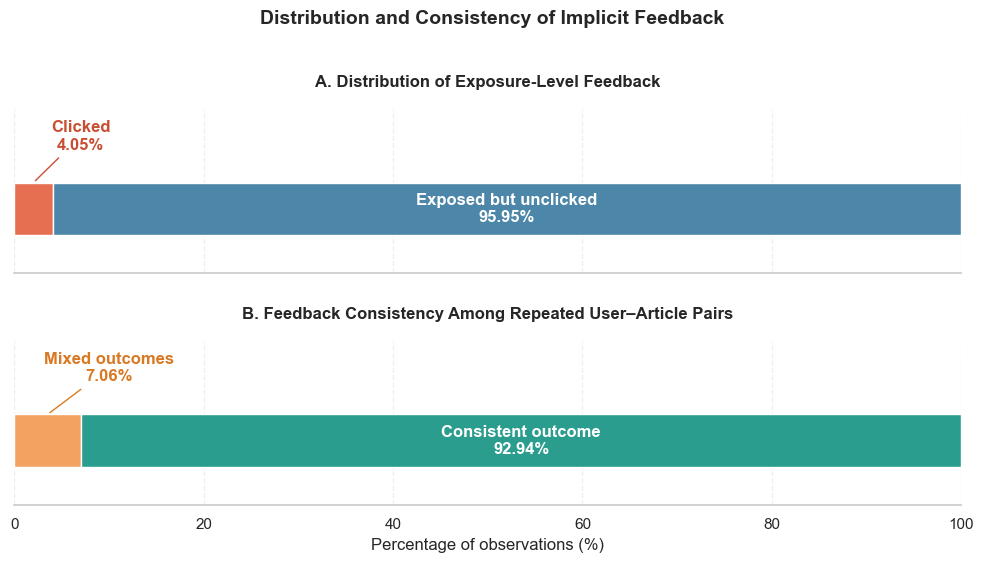

In [30]:
# Percentages for all article exposures
clicked_pct = (
    feedback_summary.loc[
        feedback_summary["Feedback type"] == "Clicked",
        "Percentage"
    ].iloc[0]
)
unclicked_pct = 100 - clicked_pct

# Percentages among repeatedly exposed user–article pairs
mixed_pct = len(mixed_feedback_pairs) / len(repeated_pairs) * 100
consistent_pct = 100 - mixed_pct

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 5.5),
    sharex=True
)

bar_height = 0.45

# Panel A: Exposure-level feedback
axes[0].barh(
    0, clicked_pct,
    height=bar_height,
    color="#E76F51",
    edgecolor="white"
)
axes[0].barh(
    0, unclicked_pct,
    left=clicked_pct,
    height=bar_height,
    color="#4C86A8",
    edgecolor="white"
)

# Put the small-segment label above the bar to prevent clipping
axes[0].annotate(
    f"Clicked\n{clicked_pct:.2f}%",
    xy=(clicked_pct / 2, bar_height / 2),
    xytext=(7, 0.48),
    ha="center",
    va="bottom",
    color="#C94F33",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-",
        color="#C94F33",
        linewidth=1
    )
)

axes[0].text(
    clicked_pct + unclicked_pct / 2,
    0,
    f"Exposed but unclicked\n{unclicked_pct:.2f}%",
    ha="center",
    va="center",
    color="white",
    fontweight="bold"
)

axes[0].set_title(
    "A. Distribution of Exposure-Level Feedback",
    pad=16,
    fontweight="bold"
)
axes[0].set_yticks([])

# Panel B: Repeated-pair consistency
axes[1].barh(
    0, mixed_pct,
    height=bar_height,
    color="#F4A261",
    edgecolor="white"
)
axes[1].barh(
    0, consistent_pct,
    left=mixed_pct,
    height=bar_height,
    color="#2A9D8F",
    edgecolor="white"
)

axes[1].annotate(
    f"Mixed outcomes\n{mixed_pct:.2f}%",
    xy=(mixed_pct / 2, bar_height / 2),
    xytext=(10, 0.48),
    ha="center",
    va="bottom",
    color="#D97924",
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="-",
        color="#D97924",
        linewidth=1
    )
)

axes[1].text(
    mixed_pct + consistent_pct / 2,
    0,
    f"Consistent outcome\n{consistent_pct:.2f}%",
    ha="center",
    va="center",
    color="white",
    fontweight="bold"
)

axes[1].set_title(
    "B. Feedback Consistency Among Repeated User–Article Pairs",
    pad=16,
    fontweight="bold"
)
axes[1].set_yticks([])
axes[1].set_xlabel("Percentage of observations (%)")

# Shared formatting
for ax in axes:
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.55, 0.85)
    ax.set_xticks(range(0, 101, 20))
    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.3
    )
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)

fig.suptitle(
    "Distribution and Consistency of Implicit Feedback",
    fontsize=14,
    fontweight="bold",
    y=1.02
)

plt.tight_layout(h_pad=2.0)

plt.savefig(
    FIGURE_DIR / "feedback_semantics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Sparsity and Temporal Patterns

### User Interaction-History Lengths

The history field records articles clicked by a user before the current
impression. Its length indicates the amount of historical preference information
available to a recommendation model.

In [31]:
behaviors["history_length"] = (
    behaviors["history"]
    .fillna("")
    .str.split()
    .str.len()
)

behaviors[
    ["user_id", "history", "history_length"]
].head()

,user_id,history,history_length
0,U65916,N51706 N40767 N12096 N9798 N38802 N54827 N57801 N5184 N23653 N44007 N36443 N43142 N11143 N53652 ...,15
1,U49985,N5056 N29975 N53234 N39603 N50032 N8422 N53580 N63314 N62646 N23203 N10807 N33835 N50455 N7242 N...,93
2,U25550,N17260 N38298 N33976 N47719 N14888 N18870 N4607,7
3,U19710,N3530 N48284 N43019 N62546 N138 N13138 N10676 N41244,8
4,U38106,N16874 N264 N48697 N51366,4


In [32]:
history_statistics = behaviors["history_length"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(history_statistics)

print(
    f"Impressions with no history: "
    f"{(behaviors['history_length'] == 0).sum():,} "
    f"({(behaviors['history_length'] == 0).mean() * 100:.2f}%)"
)

print(
    f"Impressions with fewer than 5 historical clicks: "
    f"{(behaviors['history_length'] < 5).sum():,} "
    f"({(behaviors['history_length'] < 5).mean() * 100:.2f}%)"
)

print(
    f"Impressions with fewer than 10 historical clicks: "
    f"{(behaviors['history_length'] < 10).sum():,} "
    f"({(behaviors['history_length'] < 10).mean() * 100:.2f}%)"
)

count    230117.000000
mean         32.462413
std          39.906675
min           0.000000
25%           8.000000
50%          19.000000
75%          42.000000
90%          78.000000
95%         108.000000
99%         190.000000
max         558.000000
Name: history_length, dtype: float64

Impressions with no history: 5,452 (2.37%)
Impressions with fewer than 5 historical clicks: 31,151 (13.54%)
Impressions with fewer than 10 historical clicks: 69,092 (30.02%)


| Statistic       | History length | Interpretation                                                  |
| --------------- | -------------: | --------------------------------------------------------------- |
| Mean            |          32.54 | An impression has about 33 previous clicks available on average |
| Median          |             19 | Half of impressions have 19 or fewer previous clicks            |
| 25th percentile |              8 | 25% of impressions have 8 or fewer previous clicks              |
| 75th percentile |             42 | 75% have 42 or fewer                                            |
| 90th percentile |             78 | 90% have 78 or fewer                                            |
| 95th percentile |            109 | 95% have 109 or fewer                                           |
| 99th percentile |            190 | 99% have 190 or fewer                                           |
| Maximum         |            558 | The longest recorded history contains 558 articles              |


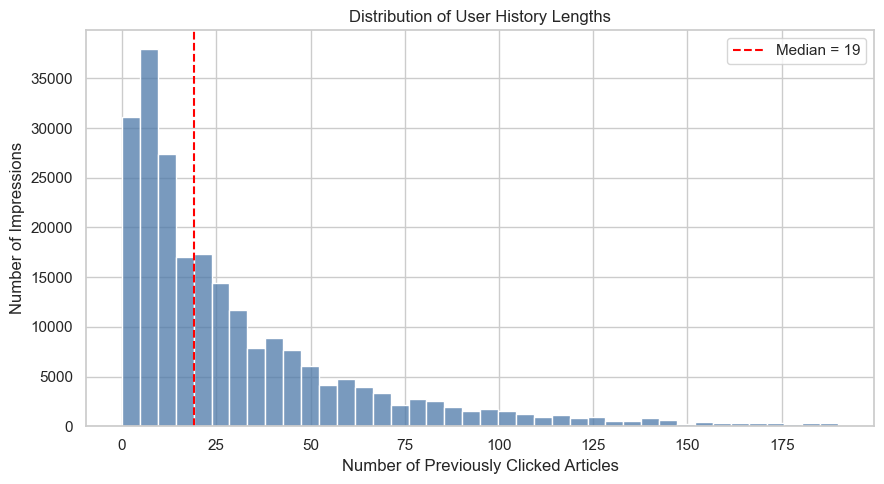

In [33]:
history_p99 = behaviors["history_length"].quantile(0.99)

history_for_plot = behaviors[
    behaviors["history_length"] <= history_p99
]

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=history_for_plot,
    x="history_length",
    bins=40,
    color="#4C78A8",
    ax=ax
)

ax.axvline(
    behaviors["history_length"].median(),
    color="red",
    linestyle="--",
    label=f"Median = {behaviors['history_length'].median():.0f}"
)

ax.set_title("Distribution of User History Lengths")
ax.set_xlabel("Number of Previously Clicked Articles")
ax.set_ylabel("Number of Impressions")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "history_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

History lengths above the 99th percentile were excluded from the visualisation to prevent extreme values from compressing the main distribution. All observations were retained in the reported summary statistics.

User interaction histories are strongly right-skewed. The median impression has 19 historical clicks available, compared with a mean of 32.54, while recorded history lengths range from 0 to 558. Although only 2.06% of impressions have no recorded history, 13.28% have fewer than five historical clicks and 29.81% have fewer than ten. Thus, a meaningful proportion of impressions provide limited historical preference information, which may weaken purely history-based personalisation and motivate the use of article-content features for short-history users.

In [34]:
user_activity = (
    behaviors.groupby("user_id")
    .agg(
        impression_count=("global_impression_id", "nunique"),
        first_impression=("time", "min"),
        last_impression=("time", "max")
    )
    .reset_index()
)

user_activity_statistics = user_activity["impression_count"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

display(user_activity_statistics)

print(f"Unique users: {len(user_activity):,}")
print(
    "Users with only one recorded impression: "
    f"{(user_activity['impression_count'] == 1).sum():,} "
    f"({(user_activity['impression_count'] == 1).mean() * 100:.2f}%)"
)

count    94057.000000
mean         2.446570
std          2.577467
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
90%          5.000000
95%          7.000000
99%         13.000000
max         69.000000
Name: impression_count, dtype: float64

Unique users: 94,057
Users with only one recorded impression: 46,230 (49.15%)


| Statistic       | Impressions per user | Meaning                                                  |
| --------------- | -------------------: | -------------------------------------------------------- |
| Mean            |                 3.14 | Each user has about 3.14 recorded impressions on average |
| Median          |                    2 | Half of users have 2 or fewer impressions                |
| 25th percentile |                    1 | At least 25% of users appear only once                   |
| 75th percentile |                    4 | 75% have 4 or fewer impressions                          |
| 90th percentile |                    6 | 90% have 6 or fewer impressions                          |
| 95th percentile |                    9 | 95% have 9 or fewer impressions                          |
| 99th percentile |                   15 | 99% have 15 or fewer impressions                         |
| Maximum         |                   62 | The most active user has 62 recorded impressions         |


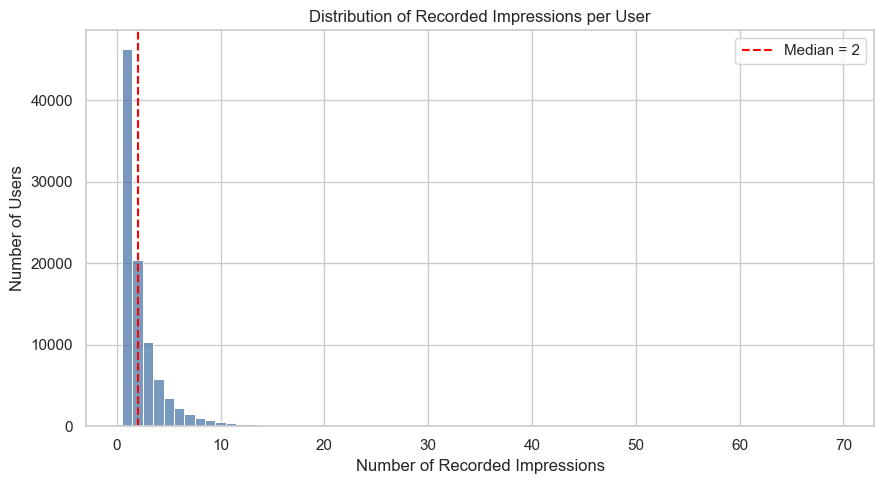

In [35]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    data=user_activity,
    x="impression_count",
    discrete=True,
    color="#4C78A8",
    ax=ax
)

ax.axvline(
    user_activity["impression_count"].median(),
    color="red",
    linestyle="--",
    label=f"Median = {user_activity['impression_count'].median():.0f}"
)

ax.set_title("Distribution of Recorded Impressions per User")
ax.set_xlabel("Number of Recorded Impressions")
ax.set_ylabel("Number of Users")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "impressions_per_user.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

User activity within the training observation period is sparse and right-skewed. Across 50,000 users, the median user appears in only two recorded impressions, while the mean is 3.14. Approximately 32.77% of users appear only once, and 75% appear no more than four times. In contrast, the most active user appears in 62 impressions. This indicates that repeated current-period observations are limited for most users, potentially restricting the reliability of user-ID-based preference estimation.

### Article Popularity and Long-Tail Behaviour

Article popularity is examined using both exposure and click counts. Exposure
counts indicate how frequently an article was included in recorded impressions,
while click counts indicate the amount of positive interaction received.

In [36]:
article_popularity = (
    exposures.groupby("news_id")
    .agg(
        exposure_count=("label", "size"),
        click_count=("label", "sum"),
        unique_exposed_users=("user_id", "nunique")
    )
    .reset_index()
)

article_popularity["ctr"] = (
    article_popularity["click_count"]
    / article_popularity["exposure_count"]
)

article_popularity.head()

,news_id,exposure_count,click_count,unique_exposed_users,ctr
0,N10005,1,0,1,0.0
1,N10007,5,0,5,0.0
2,N10008,1,0,1,0.0
3,N10010,11,0,11,0.0
4,N10011,4,0,4,0.0


In [37]:
article_popularity = (
    news[["news_id", "category", "subcategory", "title"]]
    .drop_duplicates("news_id")
    .merge(
        article_popularity,
        on="news_id",
        how="left"
    )
)

count_columns = [
    "exposure_count",
    "click_count",
    "unique_exposed_users"
]

article_popularity[count_columns] = (
    article_popularity[count_columns]
    .fillna(0)
    .astype(int)
)

article_popularity["ctr"] = (
    article_popularity["click_count"]
    .div(article_popularity["exposure_count"])
    .where(article_popularity["exposure_count"] > 0)
)

article_popularity.head()

,news_id,category,subcategory,title,exposure_count,click_count,unique_exposed_users,ctr
0,N55528,lifestyle,lifestyleroyals,"The Brands Queen Elizabeth, Prince Charles, and Prince Philip Swear By",0,0,0,NaN
1,N19639,health,weightloss,50 Worst Habits For Belly Fat,0,0,0,NaN
2,N61837,news,newsworld,The Cost of Trump's Aid Freeze in the Trenches of Ukraine's War,0,0,0,NaN
3,N53526,health,voices,I Was An NBA Wife. Here's How It Affected My Mental Health.,0,0,0,NaN
4,N38324,health,medical,"How to Get Rid of Skin Tags, According to a Dermatologist",3600,269,3429,0.074722


In [38]:
print(f"Total articles in news catalogue: {len(article_popularity):,}")

print(
    "Articles never exposed: "
    f"{(article_popularity['exposure_count'] == 0).sum():,} "
    f"({(article_popularity['exposure_count'] == 0).mean() * 100:.2f}%)"
)

print(
    "Articles with zero clicks: "
    f"{(article_popularity['click_count'] == 0).sum():,} "
    f"({(article_popularity['click_count'] == 0).mean() * 100:.2f}%)"
)

print(
    "Articles with exactly one click: "
    f"{(article_popularity['click_count'] == 1).sum():,} "
    f"({(article_popularity['click_count'] == 1).mean() * 100:.2f}%)"
)

display(
    article_popularity[
        ["exposure_count", "click_count", "unique_exposed_users", "ctr"]
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Total articles in news catalogue: 65,238
Articles never exposed: 42,467 (65.10%)
Articles with zero clicks: 56,138 (86.05%)
Articles with exactly one click: 3,250 (4.98%)


,exposure_count,click_count,unique_exposed_users,ctr
count,65238.000000,65238.000000,65238.000000,22771.000000
mean,131.586529,5.330130,114.012631,0.043181
std,990.201591,72.839218,824.876397,0.116515
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000
75%,3.000000,0.000000,3.000000,0.035626
90%,27.000000,1.000000,25.000000,0.117647
95%,225.000000,6.000000,209.000000,0.200000
99%,3607.890000,99.000000,3144.630000,0.500000


In [39]:
articles_ranked = article_popularity.sort_values(
    "click_count",
    ascending=False
).reset_index(drop=True)

def top_article_click_share(proportion):
    number_of_articles = int(
        np.ceil(len(articles_ranked) * proportion)
    )
    
    clicks_in_top_group = (
        articles_ranked
        .head(number_of_articles)["click_count"]
        .sum()
    )
    
    return clicks_in_top_group / articles_ranked["click_count"].sum() * 100

popularity_concentration = pd.Series({
    "Top 1% article click share": top_article_click_share(0.01),
    "Top 5% article click share": top_article_click_share(0.05),
    "Top 10% article click share": top_article_click_share(0.10)
})

display(popularity_concentration)

Top 1% article click share     74.661732
Top 5% article click share     96.810429
Top 10% article click share    99.259189
dtype: float64

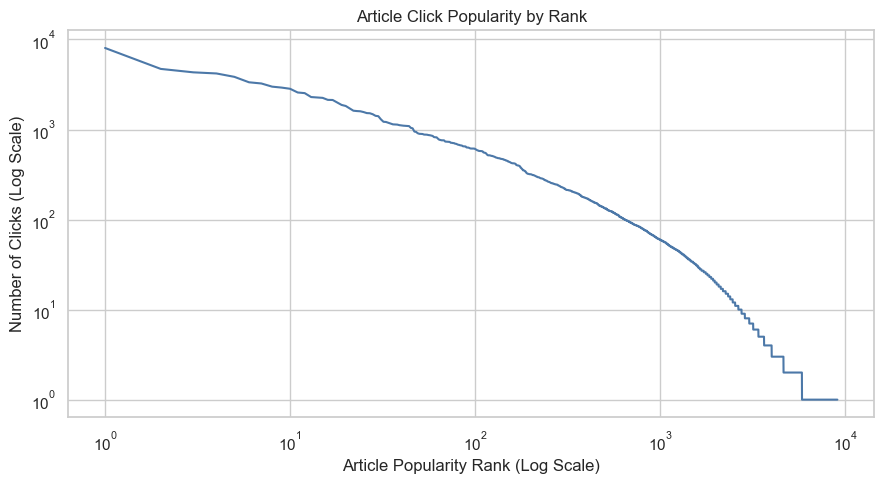

In [40]:
clicked_articles_ranked = (
    article_popularity[
        article_popularity["click_count"] > 0
    ]
    .sort_values("click_count", ascending=False)
    .reset_index(drop=True)
)

clicked_articles_ranked["popularity_rank"] = (
    clicked_articles_ranked.index + 1
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    clicked_articles_ranked["popularity_rank"],
    clicked_articles_ranked["click_count"],
    color="#4C78A8"
)

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_title("Article Click Popularity by Rank")
ax.set_xlabel("Article Popularity Rank (Log Scale)")
ax.set_ylabel("Number of Clicks (Log Scale)")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "article_click_popularity_rank.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

A small group of head articles is observed,  click counts declined rapidly as rank increases. A classic long-tail distribution is observed. Many clicks are concentrated within a small head, and there are very  few clicks per article at the long tail. However, this does not mean that users prefer head articles. A relationship may be: 
More exposure → more opportunities to click → more observed popularity 

In [41]:
def top_share(data, column, proportion):
    ranked = data.sort_values(
        column,
        ascending=False
    ).reset_index(drop=True)

    number_of_articles = int(
        np.ceil(len(ranked) * proportion)
    )

    return (
        ranked.head(number_of_articles)[column].sum()
        / ranked[column].sum()
        * 100
    )

exposure_and_click_concentration = pd.DataFrame({
    "Top article group": ["Top 1%", "Top 5%", "Top 10%"],
    "Exposure share (%)": [
        top_share(article_popularity, "exposure_count", 0.01),
        top_share(article_popularity, "exposure_count", 0.05),
        top_share(article_popularity, "exposure_count", 0.10)
    ],
    "Click share (%)": [
        top_share(article_popularity, "click_count", 0.01),
        top_share(article_popularity, "click_count", 0.05),
        top_share(article_popularity, "click_count", 0.10)
    ]
})

display(exposure_and_click_concentration)

,Top article group,Exposure share (%),Click share (%)
0,Top 1%,60.296977,74.661732
1,Top 5%,95.812949,96.810429
2,Top 10%,98.752021,99.259189


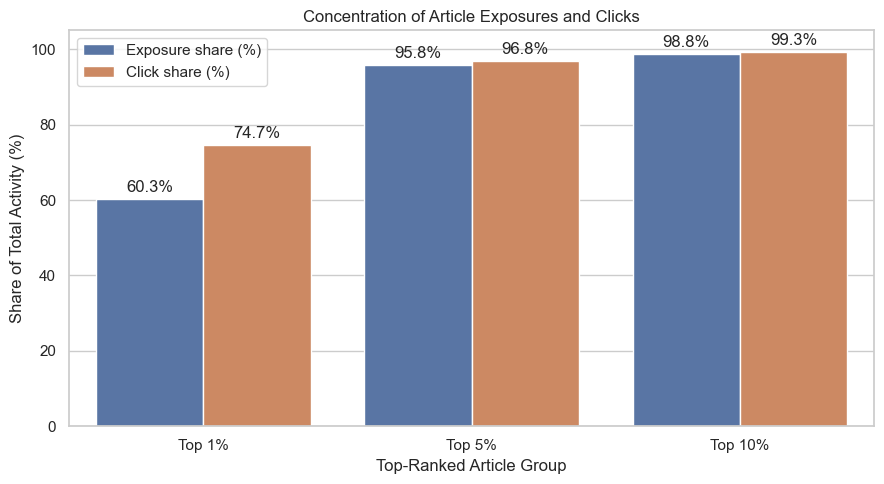

In [42]:
concentration_long = exposure_and_click_concentration.melt(
    id_vars="Top article group",
    value_vars=["Exposure share (%)", "Click share (%)"],
    var_name="Metric",
    value_name="Share (%)"
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=concentration_long,
    x="Top article group",
    y="Share (%)",
    hue="Metric",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

ax.set_title("Concentration of Article Exposures and Clicks")
ax.set_xlabel("Top-Ranked Article Group")
ax.set_ylabel("Share of Total Activity (%)")
ax.set_ylim(0, 105)
ax.legend(title="")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "exposure_click_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
exposure_ranked = article_popularity.sort_values(
    "exposure_count",
    ascending=False
).reset_index(drop=True)

same_group_results = []

for proportion, label in [
    (0.01, "Top 1%"),
    (0.05, "Top 5%"),
    (0.10, "Top 10%")
]:
    number_of_articles = int(
        np.ceil(len(exposure_ranked) * proportion)
    )

    top_exposed_group = exposure_ranked.head(number_of_articles)

    same_group_results.append({
        "Top article group": label,
        "Exposure share (%)": (
            top_exposed_group["exposure_count"].sum()
            / article_popularity["exposure_count"].sum()
            * 100
        ),
        "Click share (%)": (
            top_exposed_group["click_count"].sum()
            / article_popularity["click_count"].sum()
            * 100
        )
    })

same_group_concentration = pd.DataFrame(same_group_results)

display(same_group_concentration)

,Top article group,Exposure share (%),Click share (%)
0,Top 1%,60.296977,69.835244
1,Top 5%,95.812949,95.965226
2,Top 10%,98.752021,98.639737


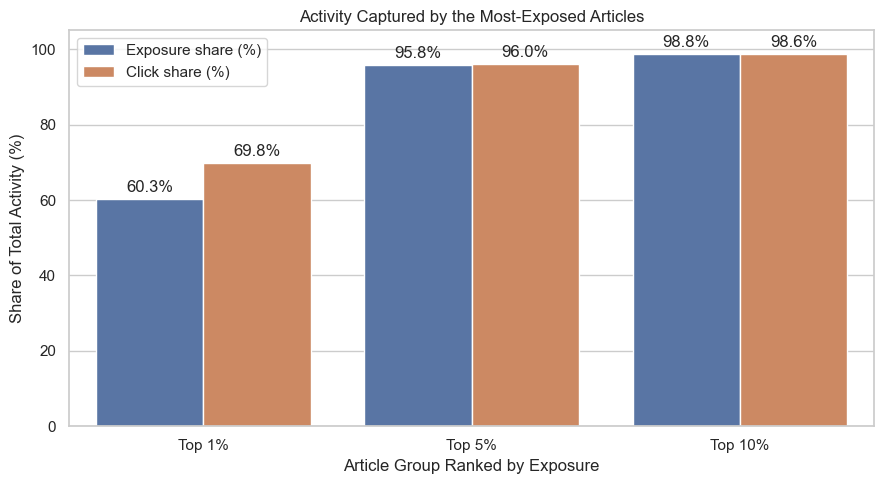

In [44]:
same_group_long = same_group_concentration.melt(
    id_vars="Top article group",
    value_vars=["Exposure share (%)", "Click share (%)"],
    var_name="Metric",
    value_name="Share (%)"
)

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=same_group_long,
    x="Top article group",
    y="Share (%)",
    hue="Metric",
    ax=ax
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

ax.set_title("Activity Captured by the Most-Exposed Articles")
ax.set_xlabel("Article Group Ranked by Exposure")
ax.set_ylabel("Share of Total Activity (%)")
ax.set_ylim(0, 105)
ax.legend(title="")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "top_exposed_articles_activity_share.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Temporal Patterns 
1. Activity across dates
2. Activity by hour of day
3. Time gaps between consecutive impressions for the same user

In [45]:
behaviors["date"] = behaviors["time"].dt.date

daily_activity = (
    behaviors.groupby("date")
    .agg(
        impression_count=("global_impression_id", "nunique"),
        unique_users=("user_id", "nunique")
    )
    .reset_index()
)

display(daily_activity)

,date,impression_count,unique_users
0,2019-11-09,13570,9865
1,2019-11-10,15048,10726
2,2019-11-11,32799,21298
3,2019-11-12,33654,22011
4,2019-11-13,31624,20884
5,2019-11-14,30270,20179
6,2019-11-15,73152,50000


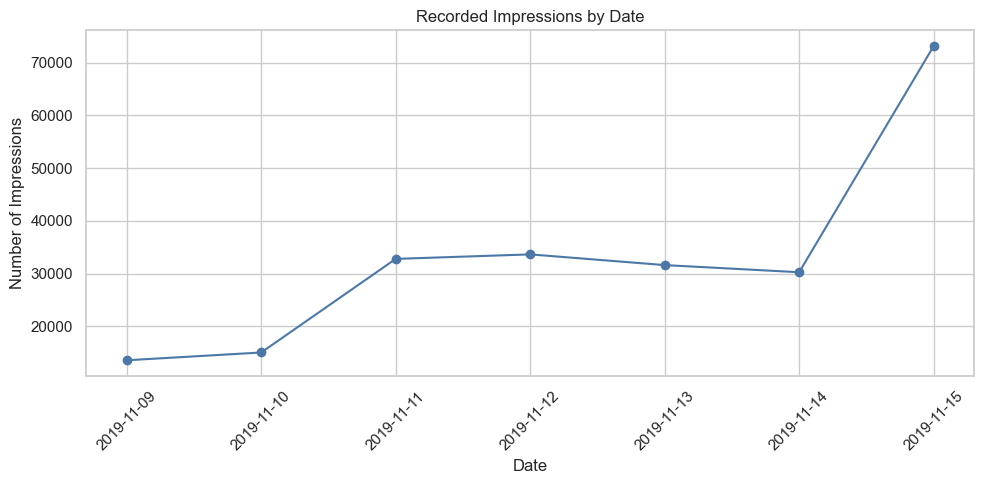

In [46]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    daily_activity["date"],
    daily_activity["impression_count"],
    marker="o",
    color="#4C78A8"
)

ax.set_title("Recorded Impressions by Date")
ax.set_xlabel("Date")
ax.set_ylabel("Number of Impressions")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "impressions_by_date.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
exposures["hour"] = exposures["time"].dt.hour

hourly_activity = (
    exposures.groupby("hour")
    .agg(
        article_exposures=("label", "size"),
        clicks=("label", "sum"),
        unique_users=("user_id", "nunique")
    )
    .reset_index()
)

hourly_activity["ctr"] = (
    hourly_activity["clicks"]
    / hourly_activity["article_exposures"]
)

display(hourly_activity)

,hour,article_exposures,clicks,unique_users,ctr
0,0,59071,2364,1334,0.040020
1,1,68492,2772,1427,0.040472
2,2,105852,4312,2281,0.040736
3,3,186560,7574,3933,0.040598
4,4,333389,13177,6947,0.039524
5,5,521495,20966,11025,0.040204
6,6,630965,25904,13864,0.041055
7,7,648315,27182,14886,0.041927
8,8,691358,29277,15977,0.042347
9,9,616737,25962,14494,0.042096


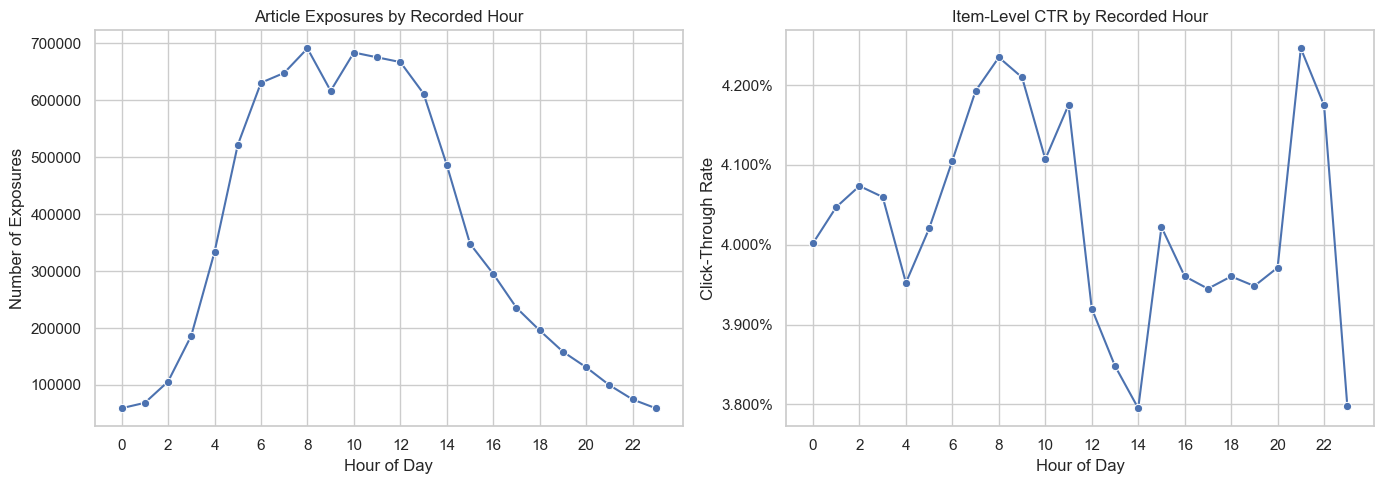

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.lineplot(
    data=hourly_activity,
    x="hour",
    y="article_exposures",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Article Exposures by Recorded Hour")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Number of Exposures")
axes[0].set_xticks(range(0, 24, 2))

sns.lineplot(
    data=hourly_activity,
    x="hour",
    y="ctr",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Item-Level CTR by Recorded Hour")
axes[1].set_xlabel("Hour of Day")
axes[1].set_ylabel("Click-Through Rate")
axes[1].set_xticks(range(0, 24, 2))

from matplotlib.ticker import PercentFormatter
axes[1].yaxis.set_major_formatter(PercentFormatter(1))

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "activity_and_ctr_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
ordered_behaviors = behaviors.sort_values(
    ["user_id", "time"]
).copy()

ordered_behaviors["previous_impression_time"] = (
    ordered_behaviors.groupby("user_id")["time"].shift(1)
)

ordered_behaviors["gap_hours"] = (
    ordered_behaviors["time"]
    - ordered_behaviors["previous_impression_time"]
).dt.total_seconds() / 3600

In [50]:
valid_gaps = ordered_behaviors["gap_hours"].dropna()

display(
    valid_gaps.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print(f"Number of valid gaps: {len(valid_gaps):,}")
print(
    f"Gaps of 24 hours or less: "
    f"{(valid_gaps <= 24).mean() * 100:.2f}%"
)

count    136060.000000
mean         16.703382
std          21.035304
min           0.000000
25%           1.665833
50%           7.240000
75%          23.857569
90%          46.610667
95%          59.771542
99%          96.381814
max         165.275833
Name: gap_hours, dtype: float64

Number of valid gaps: 136,060
Gaps of 24 hours or less: 75.55%


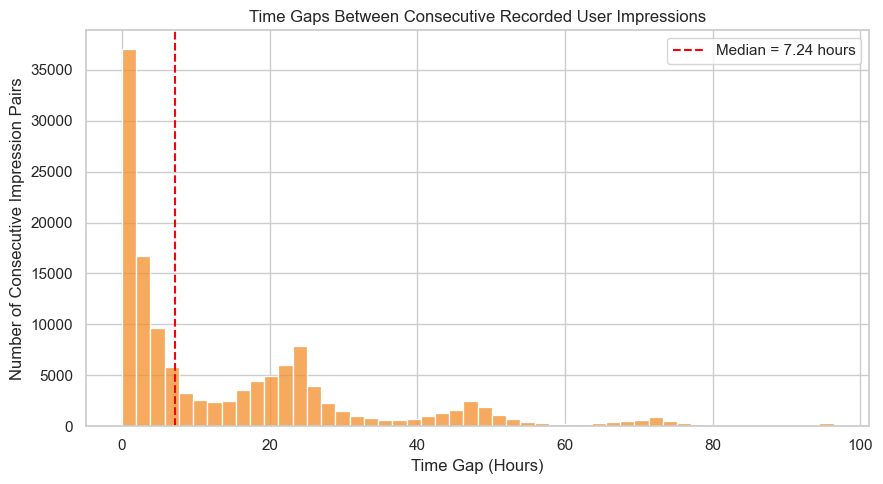

In [51]:
gap_p99 = valid_gaps.quantile(0.99)
gaps_for_plot = valid_gaps[valid_gaps <= gap_p99]

fig, ax = plt.subplots(figsize=(9, 5))

sns.histplot(
    gaps_for_plot,
    bins=50,
    color="#F28E2B",
    ax=ax
)

ax.axvline(
    valid_gaps.median(),
    color="red",
    linestyle="--",
    label=f"Median = {valid_gaps.median():.2f} hours"
)

ax.set_title("Time Gaps Between Consecutive Recorded User Impressions")
ax.set_xlabel("Time Gap (Hours)")
ax.set_ylabel("Number of Consecutive Impression Pairs")
ax.legend()

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "user_impression_time_gaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()